**AI disclaimer:** Include any disclaimers about the use of AI here, and cite the parts of the code that AI was used for.
1. Understanding the pytorch syntax, converting it to english language
2. Understanding the underlying concepts of the topics before coding
3. Confirming if the logic I am using is correct by providing pseudocode first
4. Asking help in debugging the code when error shows up

C02 Emission = 119.3g

In [166]:
import sys
if sys.version_info < (3, 10):
	raise RuntimeError("This notebook requires Python 3.10 or newer")

!pip install numpy pandas matplotlib seaborn scikit-learn torch psutil requests

# Hardware and user spercifications

import platform
import psutil
import getpass

# --- Setup: Imports ---
import os, seaborn, sklearn, random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import requests

# PyTorch imports
import torch
import torch.nn as nn
import torch.optim as optim

# Scikit-learn imports
from sklearn.preprocessing import MinMaxScaler, StandardScaler
from sklearn.model_selection import GroupShuffleSplit
from sklearn.utils import shuffle

#CODE HERE (optional): import any module needed from sklearn package

def print_system_info():
    print("="*60)
    print("SYSTEM INFORMATION")
    print("="*60)

    # OS and hardware
    print(f"Operating System : {platform.system()} {platform.release()}")
    print(f"Processor        : {platform.processor()}")
    print(f"CPU Cores        : {psutil.cpu_count(logical=True)}")
    print(f"RAM              : {round(psutil.virtual_memory().total / (1024**3), 2)} GB")

    # User
    print(f"PC Username      : {getpass.getuser()}")

    # Python and environment
    print(f"Python Version   : {platform.python_version()}")
    print(f"Working Dir      : {os.getcwd()}")

    # GPU (if PyTorch is installed)
    if torch.cuda.is_available():
        print(f"GPU Device       : {torch.cuda.get_device_name(0)}")
        print(f"CUDA Version     : {torch.version.cuda}")
    else:
        print("GPU Device       : None (CPU mode)")

    print("="*60)
    print()

print_system_info()

# Set a random seed for reproducibility
random_seed = 42
torch.manual_seed(random_seed)
np.random.seed(random_seed)
random.seed(random_seed)

SYSTEM INFORMATION
Operating System : Darwin 25.3.0
Processor        : arm
CPU Cores        : 8
RAM              : 8.0 GB
PC Username      : kabir
Python Version   : 3.14.6
Working Dir      : /Users/kabir/Desktop/Study/Level 4/4AL3/Machine-Learning/Assignments/Assignment-3
GPU Device       : None (CPU mode)



Here, we load, split, scale the data. Then we convert them to PyTorch Tensors.

In [167]:
# --- Data Loading and Preprocessing ---

# CODE HERE: Load the dataset
url = "https://openml.org/data/v1/download/21756046/parkinson-speech-uci.arff"
data = pd.read_csv(url, header=None, skiprows=783)

# Extract column names from the ARFF metadata
lines = requests.get(url).text.splitlines()
data.columns = [line.split()[1] for line in lines if line.lower().startswith("@attribute")]


# print(data.head())
# print(data.columns.tolist())
# print(data.info())


print("Dataset shape:", data.shape)
display(data.head())


# CODE HERE: Specify the features and target.
# Remove id and class

X = data.drop(columns=['id', 'class'])
y = data['class']


# Split 80/20 by subject with GroupShuffleSplit(n_splits=1, test_size=0.2,
# random_state=random_seed), using groups=data['id'].

from sklearn.model_selection import GroupShuffleSplit

gss = GroupShuffleSplit(
    n_splits=1,
    test_size=0.2,
    random_state=random_seed
)

train_idx, val_idx = next(
    gss.split(X, y, groups=data['id'])
)


y_train = y.iloc[train_idx]
y_val = y.iloc[val_idx]

X_train = X.iloc[train_idx]
X_val = X.iloc[val_idx]



# CODE HERE: Scale the features
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_val = scaler.transform(X_val)



# CODE HERE: Convert to PyTorch Tensors

# import torch

X_train = torch.tensor(X_train, dtype=torch.float32)
X_val = torch.tensor(X_val, dtype=torch.float32)

y_train = torch.tensor(y_train.to_numpy(), dtype=torch.float32).reshape(-1, 1)
y_val = torch.tensor(y_val.to_numpy(), dtype=torch.float32).reshape(-1, 1)



# Display training and validation shapes
print(f"Training features shape: {X_train.shape}")
print(f"Validation features shape: {X_val.shape}")

Dataset shape: (756, 755)


,id,gender,PPE,DFA,RPDE,numPulses,numPeriodsPulses,meanPeriodPulses,stdDevPeriodPulses,locPctJitter,...,tqwt_kurtosisValue_dec_28,tqwt_kurtosisValue_dec_29,tqwt_kurtosisValue_dec_30,tqwt_kurtosisValue_dec_31,tqwt_kurtosisValue_dec_32,tqwt_kurtosisValue_dec_33,tqwt_kurtosisValue_dec_34,tqwt_kurtosisValue_dec_35,tqwt_kurtosisValue_dec_36,class
0,0.0,1.0,0.85247,0.71826,0.57227,240.0,239.0,0.008064,0.000087,0.00218,...,1.5620,2.6445,3.8686,4.2105,5.1221,4.4625,2.6202,3.0004,18.9405,1.0
1,0.0,1.0,0.76686,0.69481,0.53966,234.0,233.0,0.008258,0.000073,0.00195,...,1.5589,3.6107,23.5155,14.1962,11.0261,9.5082,6.5245,6.3431,45.1780,1.0
2,0.0,1.0,0.85083,0.67604,0.58982,232.0,231.0,0.008340,0.000060,0.00176,...,1.5643,2.3308,9.4959,10.7458,11.0177,4.8066,2.9199,3.1495,4.7666,1.0
3,1.0,0.0,0.41121,0.79672,0.59257,178.0,177.0,0.010858,0.000183,0.00419,...,3.7805,3.5664,5.2558,14.0403,4.2235,4.6857,4.8460,6.2650,4.0603,1.0
4,1.0,0.0,0.32790,0.79782,0.53028,236.0,235.0,0.008162,0.002669,0.00535,...,6.1727,5.8416,6.0805,5.7621,7.7817,11.6891,8.2103,5.0559,6.1164,1.0


Training features shape: torch.Size([603, 753])
Validation features shape: torch.Size([153, 753])


Next, we define the Neural Network (NN).

In [168]:
# --- Model Definition ---

# CODE HERE: define the asked NN here

class NeuralNetwork(nn.Module):
    def __init__(self, input_size):
        super().__init__()

        self.fc1 = nn.Linear(input_size, 32)
        self.relu1 = nn.ReLU()

        self.fc2 = nn.Linear(32, 16)
        self.relu2 = nn.ReLU()

        self.fc3 = nn.Linear(16, 1)
        self.sigmoid = nn.Sigmoid()

    def forward(self, x):
        x = self.fc1(x)
        x = self.relu1(x)

        x = self.fc2(x)
        x = self.relu2(x)

        x = self.fc3(x)
        x = self.sigmoid(x)

        return x


# model = NeuralNetwork(input_size=752)
# prediction = model(X)

# input_size = input_features

input_features = X_train.shape[1]
print(f"Model will accept {input_features} input features.")
print("--- 3. Model Class Defined ---")

Model will accept 753 input features.
--- 3. Model Class Defined ---


Part 1:

In [ ]:
import copy

def calculate_full_loss(model, criterion, X, y):
    """Helper function to calculate loss over an entire dataset."""
    model.eval() # Set model to evaluation mode
    with torch.no_grad(): # Disable gradient calculation
        outputs = model(X)
        loss = criterion(outputs, y)
    model.train() # Set model back to train mode
    return loss.item()

def stochastic_gradient_descent(model, criterion, optimizer, X_train, y_train, X_val, y_val,
                                max_iterations, check_every, patience, threshold):

    #CODE HERE: fill function. Use calculate_full_loss function for loss.
    
    train_losses = []
    val_losses = []
    iterations = []

    # INITIALIZATIONS
    best_val_loss = float('inf')
    best_model_state = None
    patience_counter = 0
    stop_iteration = None
    


    for iteration in range(1, max_iterations + 1):

        # Clear previous gradients
        optimizer.zero_grad()

        # Select one training sample
        x = X_train[iteration - 1]
        y = y_train[iteration - 1]

        # Forward pass
        output = model(x)

        # Calculate loss
        loss = criterion(output, y)

        # Backpropagation
        loss.backward()

        # Update weights
        optimizer.step()

        # Check losses every check_every iterations
        if iteration % check_every == 0:

            train_loss = calculate_full_loss(
                model, criterion, X_train, y_train
            )

            val_loss = calculate_full_loss(
                model, criterion, X_val, y_val
            )

            train_losses.append(train_loss)
            val_losses.append(val_loss)
            iterations.append(iteration)

            # Check validation improvement
            if val_loss < best_val_loss:
                best_val_loss = val_loss
                best_model_state = copy.deepcopy(model.state_dict())
                patience_counter = 0
            else:
                patience_counter += 1

            # Check stopping conditions
            training_plateau = train_loss <= threshold

            # Record the first stopping iteration
            if stop_iteration is None:
                if training_plateau or patience_counter >= patience:
                    stop_iteration = iteration
                    break


    return train_losses, val_losses, iterations, stop_iteration, best_model_state

Training and plot:

Stop iteration: 210
Plotting Part 1 results...


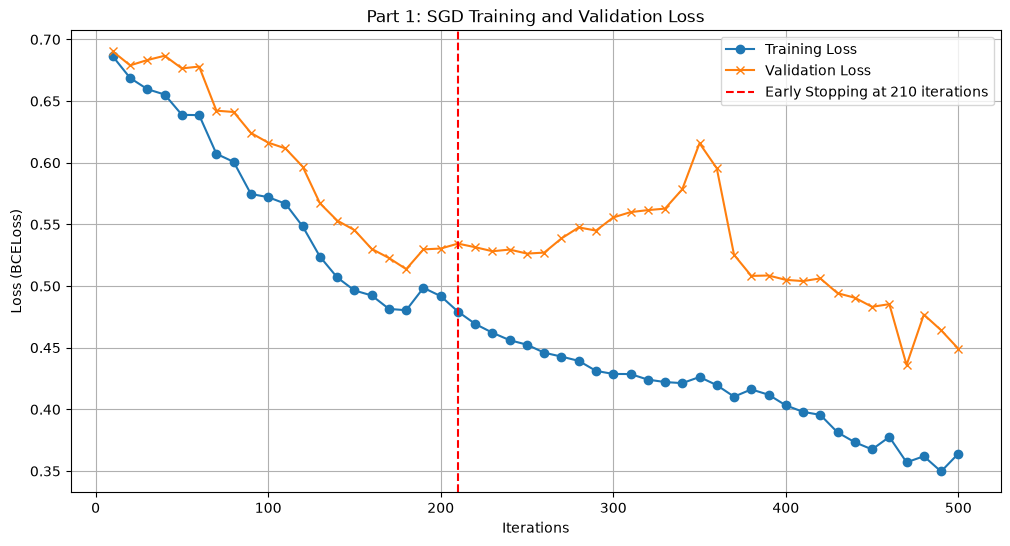


Accuracy of Early-Stopped Model on Validation Set: 81.05%


In [174]:
# --- Hyperparameters for Part 1 ---
LEARNING_RATE = 0.01
MAX_ITERATIONS = 500
CHECK_EVERY = 10
PATIENCE = 3
THRESHOLD = 1e-2

# --- Model Initialization ---

#CODE HERE
model = NeuralNetwork(input_features)
criterion = nn.BCELoss()

optimizer = torch.optim.SGD(
    model.parameters(),
    lr=LEARNING_RATE
)

# --- Run Training ---

#CODE HERE
train_losses_sgd, val_losses_sgd, iterations_sgd, stop_iter, best_model_state = stochastic_gradient_descent(model, criterion, optimizer, X_train, y_train, X_val, y_val,
                                max_iterations=MAX_ITERATIONS, check_every=CHECK_EVERY, patience=PATIENCE, threshold=THRESHOLD)

# DEBUG
print("Stop iteration:", stop_iter)
if stop_iter is None:
    stop_iter = max_iterations
    print("Early stopping was not triggered. Maximum iterations reached.")



# --- Plotting Results ---
print("Plotting Part 1 results...")
plt.figure(figsize=(12, 6))
plt.plot(iterations_sgd, train_losses_sgd, label='Training Loss', marker='o')
plt.plot(iterations_sgd, val_losses_sgd, label='Validation Loss', marker='x')
plt.axvline(x=stop_iter, color='red', linestyle='--',
            label=f'Early Stopping at {stop_iter} iterations')
plt.title('Part 1: SGD Training and Validation Loss')
plt.xlabel('Iterations')
plt.ylabel('Loss (BCELoss)')
plt.legend()
plt.grid(True)
plt.show()

# --- Final Accuracy ---

#CODE HERE
# Restore the model with the lowest validation loss
model.load_state_dict(best_model_state)

# Evaluate on validation data
model.eval()

with torch.no_grad():

    #CODE HERE
    outputs = model(X_val)
    predictions = (outputs >= 0.5).float()

    accuracy = (predictions == y_val).float().mean().item()


    print(f"\nAccuracy of Early-Stopped Model on Validation Set: {accuracy * 100:.2f}%")


Part 2:

In [183]:
from torch.utils.data import TensorDataset, DataLoader

def train_with_minibatch(model, criterion, optimizer, X_train, y_train, X_val, y_val,
                         num_iterations, batch_size, check_every):

    # Max iterations, patience, threshold are missing

    #CODE HERE: fill function

    train_dataset = TensorDataset(X_train, y_train)

    # Create batches
    train_loader = DataLoader(
        train_dataset,
        batch_size=batch_size,
        shuffle=True
    )


    # check_every = max(1, len(train_loader) // 10)

    train_losses = []
    val_losses = []
    iterations = []

    # INITIALIZATIONS
    best_val_loss = float('inf')
    best_model_state = None

    iteration = 0


    while iteration < num_iterations:
        for batch_X, batch_y in train_loader:
            if iteration >= num_iterations:
                break
            iteration += 1
            # Train nn with that batch
            optimizer.zero_grad()

            output = model(batch_X)

            loss = criterion(output, batch_y)

            loss.backward()

            optimizer.step()

            if iteration % check_every == 0:

                train_loss = calculate_full_loss(
                    model, criterion, X_train, y_train
                )

                val_loss = calculate_full_loss(
                    model, criterion, X_val, y_val
                )

                train_losses.append(train_loss)
                val_losses.append(val_loss)
                iterations.append(iteration)

                # Check validation improvement
                if val_loss < best_val_loss:
                    best_val_loss = val_loss
                    best_model_state = copy.deepcopy(model.state_dict())


    return train_losses, val_losses, iterations, model # Return the final model


Training and plot:

Plotting Part 2 comparison...


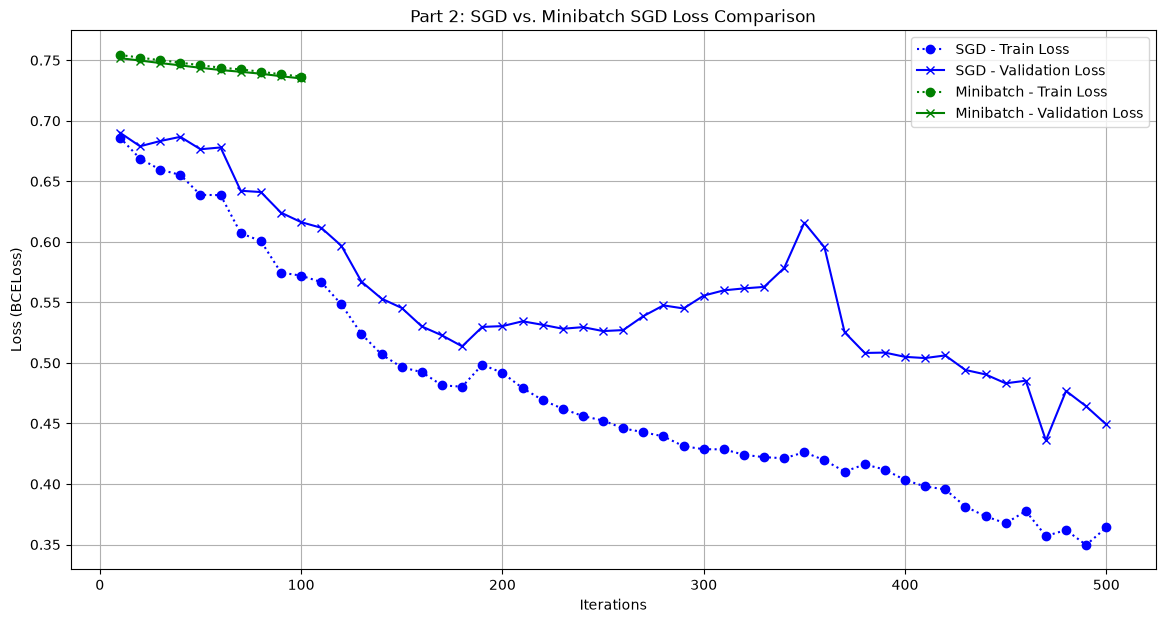

In [184]:
# --- Hyperparameters for Part 2 ---
LEARNING_RATE_MB = 0.001
NUM_ITERATIONS_MB =100
BATCH_SIZE = 20
CHECK_EVERY_MB = 10

# --- Model Initialization ---

#CODE HERE
mini_sgd_nn = NeuralNetwork(input_features)


# --- Run Minibatch Training ---



#CODE HERE

optimizer_mb = torch.optim.SGD(
    mini_sgd_nn.parameters(),
    lr=LEARNING_RATE_MB
)

train_losses_mb, val_losses_mb, iterations_mb, model = train_with_minibatch(mini_sgd_nn, criterion, optimizer_mb, X_train, y_train, X_val, y_val,
                         num_iterations=NUM_ITERATIONS_MB, batch_size=BATCH_SIZE, check_every=CHECK_EVERY_MB)

# --- Plotting Comparison ---
print("Plotting Part 2 comparison...")
plt.figure(figsize=(14, 7))

# SGD (Part 1)
plt.plot(iterations_sgd, train_losses_sgd, label='SGD - Train Loss', linestyle=':', color='blue', marker='o')
plt.plot(iterations_sgd, val_losses_sgd, label='SGD - Validation Loss', linestyle='-', color='blue', marker='x')

# Minibatch (Part 2)
plt.plot(iterations_mb, train_losses_mb, label='Minibatch - Train Loss', linestyle=':', color='green', marker='o')
plt.plot(iterations_mb, val_losses_mb, label='Minibatch - Validation Loss', linestyle='-', color='green', marker='x')

plt.title('Part 2: SGD vs. Minibatch SGD Loss Comparison')
plt.xlabel('Iterations')
plt.ylabel('Loss (BCELoss)')
plt.legend()
plt.grid(True)
plt.show()

Performance evaluation:

In [186]:
# --- Performance Metrics Comparison ---

def get_metrics(model, X_val, y_val):
    """Helper function to get accuracy, precision, and recall."""
    model.eval()
    with torch.no_grad():
        y_pred_prob = model(X_val)
        y_pred = (y_pred_prob > 0.5).int().numpy() # Convert to numpy
        y_true = y_val.numpy()

        # CODE HERE: Implement accuracy, precision, and recall yourself using y_true and y_pred
        TP = ((y_true == 1) & (y_pred == 1)).sum()
        TN = ((y_true == 0) & (y_pred == 0)).sum()
        FP = ((y_true == 0) & (y_pred == 1)).sum()
        FN = ((y_true == 1) & (y_pred == 0)).sum()

        acc = (TP + TN) / (TP + TN + FP + FN)

        pre = TP / (TP + FP) if (TP + FP) > 0 else 0

        rec = TP / (TP + FN) if (TP + FN) > 0 else 0
        
    return acc, pre, rec

# Get metrics for Part 1 (Early-Stopped SGD Model)

#CODE HERE: USING get_metrics function

model_sgd = NeuralNetwork(input_features)
model_sgd.load_state_dict(best_model_state)

acc_sgd, pre_sgd, rec_sgd = get_metrics(
    model_sgd, X_val, y_val
)


# Get metrics for Part 2 (Final Minibatch Model)

#CODE HERE: USING get_metrics function

acc_mb, pre_mb, rec_mb = get_metrics(
    model, X_val, y_val
)


# --- Show Results in a Table ---
results = {
    'Metric': ['Accuracy', 'Precision', 'Recall'],
    'Part 1: Early-Stopped SGD': [f"{acc_sgd:.4f}", f"{pre_sgd:.4f}", f"{rec_sgd:.4f}"],
    'Part 2: Minibatch SGD': [f"{acc_mb:.4f}", f"{pre_mb:.4f}", f"{rec_mb:.4f}"]
}

results_df = pd.DataFrame(results)
print("\n--- Final Performance Metrics on Validation Set ---")

from IPython.display import display
display(results_df)



--- Final Performance Metrics on Validation Set ---


,Metric,Part 1: Early-Stopped SGD,Part 2: Minibatch SGD
0,Accuracy,0.8105,0.2810
1,Precision,0.8417,1.0000
2,Recall,0.9099,0.0090


***Part 3***

In [ ]:
class FeedForwardNetWithDropout(nn.Module):
    """
    TODO: Complete this neural network class to include dropout layers.

    The dropout_rate parameter should control the dropout probability.
    When dropout_rate=0.0, no dropout is applied.
    """
    def __init__(self, input_size, dropout_rate=0.0):
        super(FeedForwardNetWithDropout, self).__init__()

        #CODE HERE: Define the NN architecture
        self.fc1 = nn.Linear(input_size, 32)
        self.relu1 = nn.ReLU()
        self.dropout1 = nn.Dropout(dropout_rate)

        self.fc2 = nn.Linear(32, 16)
        self.relu2 = nn.ReLU()
        self.dropout2 = nn.Dropout(dropout_rate)

        self.fc3 = nn.Linear(16, 1)
        self.sigmoid = nn.Sigmoid()


    def forward(self, x):
        """
        TODO: Implement the forward pass.

        Return the final output.
        """

        x = self.fc1(x)
        x = self.relu1(x)
        x = self.dropout1(x)

        x = self.fc2(x)
        x = self.relu2(x)
        x = self.dropout2(x)

        x = self.fc3(x)
        out = self.sigmoid(x)


        return out




In [187]:
def calculate_accuracy(model, X, y):
    """
    TODO: Implement accuracy calculation.


    """
    # CODE HERE: Set model to evaluation mode
    model.eval()

    with torch.no_grad():
        # CODE HERE: Get model outputs
        outputs = model(X)
        predictions = (outputs >= 0.5).float()
        accuracy = (predictions == y).float().mean().item()

    return accuracy


In [ ]:
def train_with_dropout(model, criterion, optimizer, X_train, y_train, X_val, y_val,
                                 num_iterations, batch_size, check_every):
    """
    TODO: Complete this training function to support dropout.

    """
    # CODE HERE: Use need to fill like using miniSGD in part 2

    return train_losses, val_losses, train_accs, val_accs, iterations

In [ ]:
DROPOUT_RATES =
LEARNING_RATE_DROPOUT =
NUM_ITERATIONS_DROPOUT =
BATCH_SIZE_DROPOUT =
CHECK_EVERY_DROPOUT =

dropout_results = {}

for dropout_rate in DROPOUT_RATES:
    print(f"\n--- Training with Dropout Rate = {dropout_rate} ---")

    # CODE HERE: Initialize model with current dropout_rate
    model = None  # REPLACE WITH YOUR CODE


    # Train the model
    train_losses, val_losses, train_accs, val_accs, iterations = train_with_dropout(
        model, criterion, optimizer,
        X_train_t, y_train_t, X_val_t, y_val_t,
        NUM_ITERATIONS_DROPOUT, BATCH_SIZE_DROPOUT, CHECK_EVERY_DROPOUT
    )

    # Store results for later comparison
    dropout_results[dropout_rate] = {
        'train_losses': train_losses,
        'val_losses': val_losses,
        'train_accs': train_accs,
        'val_accs': val_accs,
        'iterations': iterations,
        'model': model
    }

    print(f"Final Training Accuracy: {train_accs[-1]*100:.2f}%")
    print(f"Final Validation Accuracy: {val_accs[-1]*100:.2f}%")


In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Plot accuracies/validations vs dropouts
# CODE HERE: inject points in plots

axes[0].set_title('Part 3: Training Accuracy vs Dropout Rate', fontsize=14, fontweight='bold')
axes[0].set_xlabel('Iterations')
axes[0].set_ylabel('Training Accuracy (%)')
axes[0].legend()
axes[0].grid(True, alpha=0.3)


# CODE HERE: inject points in plots

axes[1].set_title('Part 3: Validation Accuracy vs Dropout Rate', fontsize=14, fontweight='bold')
axes[1].set_xlabel('Iterations')
axes[1].set_ylabel('Validation Accuracy (%)')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()



fig, axes = plt.subplots(1, 2, figsize=(16, 6))


axes[0].set_title('Part 3: Training Loss vs Dropout Rate', fontsize=14, fontweight='bold')
axes[0].set_xlabel('Iterations')
axes[0].set_ylabel('Training Loss (BCE)')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

axes[1].set_title('Part 3: Validation Loss vs Dropout Rate', fontsize=14, fontweight='bold')
axes[1].set_xlabel('Iterations')
axes[1].set_ylabel('Validation Loss (BCE)')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [ ]:
# CODE HERE: Create a summary dataframe with the following columns:

dropout_summary = {
    'Dropout Rate': [],
    'Final Train Acc (%)': [],
    'Final Val Acc (%)': [],
    'Final Train Loss': [],
    'Final Val Loss': []
}

# CODE HERE: Fill the summary dictionary by looping through DROPOUT_RATES

dropout_df = pd.DataFrame(dropout_summary)
display(dropout_df)



#EXPLAIN HERE: Based on your results, answer the following questions:


1. Does dropout prevent the model from overfitting?


2. Do validation accuracy and validation loss agree on which dropout rate is
   best? If not, explain why they can disagree.


3. Which dropout rate shows the best generalization?


4. Which dropout rate would you recommend for this dataset and why?


5. What are the trade-offs between low dropout (0.1) and high dropout (0.5)?


***Part 4***

In [ ]:
def train_with_minibatch_l2(model, criterion, optimizer, X_train, y_train, X_val, y_val,
                            num_iterations, batch_size, check_every):
    """
    #TODO: Implement training with L2 regularization.

    """
    n_samples = X_train.shape[0]
    train_losses, val_losses, iterations = [], [], []

    X_train_shuffled = X_train.clone()
    y_train_shuffled = y_train.clone()
    current_idx = 0

    for i in range(num_iterations + 1):
        if current_idx + batch_size > n_samples:
            X_train_np, y_train_np = shuffle(X_train_shuffled.numpy(), y_train_shuffled.numpy(),
                                            random_state=random_seed + i)
            X_train_shuffled = torch.tensor(X_train_np, dtype=torch.float32)
            y_train_shuffled = torch.tensor(y_train_np, dtype=torch.float32)
            current_idx = 0

        X_batch = X_train_shuffled[current_idx : current_idx + batch_size]
        y_batch = y_train_shuffled[current_idx : current_idx + batch_size]
        current_idx += batch_size

        # CODE HERE: Complete the training

        if i % check_every == 0:
            # CODE HERE: Calculate and store training and validation losses
            pass

    return train_losses, val_losses, iterations


In [ ]:
def train_with_minibatch_l1(model, criterion, optimizer, X_train, y_train, X_val, y_val,
                            num_iterations, batch_size, check_every, lambda_l1):
    """
    TODO: Implement training with manual L1 regularization.
    """
    n_samples = X_train.shape[0]
    train_losses, val_losses, iterations = [], [], []

    X_train_shuffled = X_train.clone()
    y_train_shuffled = y_train.clone()
    current_idx = 0

    for i in range(num_iterations + 1):
        if current_idx + batch_size > n_samples:
            X_train_np, y_train_np = shuffle(X_train_shuffled.numpy(), y_train_shuffled.numpy(),
                                            random_state=random_seed + i)
            X_train_shuffled = torch.tensor(X_train_np, dtype=torch.float32)
            y_train_shuffled = torch.tensor(y_train_np, dtype=torch.float32)
            current_idx = 0

        X_batch = X_train_shuffled[current_idx : current_idx + batch_size]
        y_batch = y_train_shuffled[current_idx : current_idx + batch_size]
        current_idx += batch_size

        model.train()
        optimizer.zero_grad()

        # CODE HERE: Calculate outputs and BCE loss
        outputs = None  # REPLACE WITH YOUR CODE
        loss = None  # REPLACE WITH YOUR CODE

        # CODE HERE: Calculate L1 penalty

        l1_penalty = 0

        # CODE HERE: Calculate total loss
        total_loss = None  # REPLACE WITH YOUR CODE

        # TODO: Backpropagate and update weights using total_loss

        if i % check_every == 0:
            # CODE HERE: Calculate losses
            pass

    return train_losses, val_losses, iterations

In [ ]:
LAMBDA_L2_VALUES = [0.0, 1e-4, 1e-3]  # 0.0 is the "No regularization" row
LEARNING_RATE_L2 =
NUM_ITERATIONS_L2 =
BATCH_SIZE_L2 =
CHECK_EVERY_L2 =

l2_results = {}

for lambda_l2 in LAMBDA_L2_VALUES:
    print(f"\n--- Training with L2 λ = {lambda_l2} ---")

    # CODE HERE: Initialize & train the model (use original FeedForwardNet, no dropout)
    model =

    train_losses, val_losses, iterations = train_with_minibatch_l2(
        model, criterion, optimizer,
        X_train_t, y_train_t, X_val_t, y_val_t,
        NUM_ITERATIONS_L2, BATCH_SIZE_L2, CHECK_EVERY_L2
    )

    # CODE HERE: Calculate final validation accuracy
    final_accuracy =

    # Store results
    l2_results[lambda_l2] = {
        'train_losses': train_losses,
        'val_losses': val_losses,
        'iterations': iterations,
        'final_accuracy': final_accuracy,
        'model': model
    }

    print(f"Final Validation Accuracy: {final_accuracy*100:.2f}%")

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# TODO: Plot training/validation loss for all L2 values
# CODE HERE: Inject points to plots

axes[0].set_title('Part 4a: Training Loss with L2 Regularization', fontsize=14, fontweight='bold')
axes[0].set_xlabel('Iterations')
axes[0].set_ylabel('Training Loss (BCE)')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# CODE HERE: Inject points to plots

axes[1].set_title('Part 4a: Validation Loss with L2 Regularization', fontsize=14, fontweight='bold')
axes[1].set_xlabel('Iterations')
axes[1].set_ylabel('Validation Loss (BCE)')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [ ]:
LAMBDA_L1 = 1e-4

# CODE HERE : Initialize model, criterion, and optimizer for L1 experiment
model_l1 =
criterion_l1 =
optimizer_l1 =

# Train with L1
train_losses_l1, val_losses_l1, iterations_l1 = train_with_minibatch_l1(
    model_l1, criterion_l1, optimizer_l1,
    X_train_t, y_train_t, X_val_t, y_val_t,
    NUM_ITERATIONS_L2, BATCH_SIZE_L2, CHECK_EVERY_L2, LAMBDA_L1
)

# CODE HERE: Calculate final validation accuracy for L1 model
final_accuracy_l1 =

print(f"Final Validation Accuracy (L1): {final_accuracy_l1*100:.2f}%")

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# CODE HERE: inject points to plots

axes[0].set_title('Part 4b: Training Loss - L1 vs L2', fontsize=14, fontweight='bold')
axes[0].set_xlabel('Iterations')
axes[0].set_ylabel('Training Loss (BCE)')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# CODE HERE: inject points to plots

axes[1].set_title('Part 4b: Validation Loss - L1 vs L2', fontsize=14, fontweight='bold')
axes[1].set_xlabel('Iterations')
axes[1].set_ylabel('Validation Loss (BCE)')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


In [ ]:

# TODO: Create a summary dataframe with columns:
# Fill rows for: No regularization, L2 (1e-4), L2 (1e-3), L1 (1e-4)
# Sparsity (%) = percentage of all model parameters with |value| < 1e-3
# CODE HERE

reg_summary = {
    'Regularization': [],
    'Final Val Acc (%)': [],
    'Final Train Loss': [],
    'Final Val Loss': [],
    'Sparsity (%)': []
}

# TODO: Fill the summary dictionary
# CODE HERE

reg_df = pd.DataFrame(reg_summary)
display(reg_df)



#EXPLAIN HERE: Based on your experiments, answer the following questions:


1. What happens when you increase L2 strength from λ=1e-4 to λ=1e-3?

   
2. Which regularization method (L1/L2 or no regulation) achieves better generalization for this Parkinson's dataset?

3. How does L1 affect model sparsity compared to L2, and why might that be
   useful for this dataset?